# Application 09 · First hits and all roots

**Builds on:** [Lecture 09](../notebooks/09_validated_roots.ipynb) (exclusion, interval Newton, complete searches), Lectures 07–08, and Lecture 03 (conditioning).

**Time:** about 75 minutes. **You will certify:**

- **Part A:** the *first* intersection of a ray with a torus, for every pixel of a small image;
- **Part B:** every real root of Wilkinson's polynomial, and of two nearby polynomials.

Both parts depend on the **completeness** idea of Lecture 09: we must account for every part of the search interval, not just report the roots we happened to find.

## Google Colab setup — run this cell first

**Local Jupyter:** this cell skips Colab setup; use your installed course environment.

Use a **CPU Python runtime** (Python 3.12 or newer). Run the next cell and select
**vc_runtime.zip** from this edition when prompted. It loads the course helpers
and installs the arithmetic libraries. Repeat setup whenever you get a new runtime.
No Drive mounting or local Python installation is required.
Use this setup instead of the local installation and kernel-selection instructions
in the original course text.

Save a copy of this notebook in Drive, or download it after editing. Files created
by the project are under `/content/validated-course/build/certificates/`; download
those separately from Colab's Files panel. Runtime files are temporary.

Open other course notebooks using **File → Upload notebook**, choosing them from
the extracted course folder. Relative course links are intended for local Jupyter
and do not open sibling notebooks automatically in Colab.


In [1]:
try:
    import google.colab
except ImportError:
    print("Local Jupyter: using the installed course environment.")
else:
    import hashlib
    from pathlib import Path
    import subprocess
    import sys
    from google.colab import files

    if sys.version_info < (3, 12):
        raise RuntimeError("This course needs a Python 3.12 or newer Colab runtime.")

    # Upload the small companion file supplied with the Colab course edition.
    expected_hash = '833652c4a440f1c3a22bc6e68c59d533b41e6f9f1ff0b4af226f8fbee2244c1a'
    runtime_zip = Path("/content") / ("vc-course-" + expected_hash + ".zip")
    if not runtime_zip.exists():
        print("Select vc_runtime.zip from the extracted Colab course folder.")
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload only vc_runtime.zip, then run this cell again.")
        archive_bytes = next(iter(uploaded.values()))
        if hashlib.sha256(archive_bytes).hexdigest() != expected_hash:
            raise ValueError("Wrong vc_runtime.zip: use the one supplied with this notebook.")
        runtime_zip.write_bytes(archive_bytes)

    if hashlib.sha256(runtime_zip.read_bytes()).hexdigest() != expected_hash:
        raise ValueError("The cached vc archive has changed; start a fresh runtime.")

    # Keep Colab's existing NumPy and plotting stack when they satisfy these bounds.
    # Install MPFR/Arb bindings, not the full local Jupyter environment.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        'numpy>=1.26', 'matplotlib>=3.8', 'gmpy2==2.3.1', 'python-flint==0.9.0', 'jupytext>=1.16'
    ])
    import gmpy2
    import flint
    if gmpy2.version() != "2.3.1" or flint.__version__ != "0.9.0":
        raise RuntimeError("Old arithmetic libraries are still loaded. Restart the session and run setup first.")

    if str(runtime_zip) not in sys.path:
        sys.path.insert(0, str(runtime_zip))

    import vc
    if not vc.__file__.startswith(str(runtime_zip) + "/"):
        raise RuntimeError("Another vc copy is already loaded. Start a fresh runtime.")

    # Preserve the relative output paths used by the project notebooks.
    import os
    working_folder = Path("/content/validated-course") / 'applications'
    working_folder.mkdir(parents=True, exist_ok=True)
    os.chdir(working_folder)
    print("Course helpers ready:", vc.__version__)

Local Jupyter: using the installed course environment.


In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from vc.intervals import RationalInterval as Interval
from vc.autodiff import Dual
from vc.roots import inspect_root, isolate_roots, RootDecision

# Part A · Ray tracing an implicit surface

A torus with radii R = 1 (center of the tube) and r = 1/5 (tube radius), around the z-axis, is the zero set of

$$T(x,y,z)=\left(x^2+y^2+z^2+R^2-r^2\right)^2-4R^2\left(x^2+y^2\right).$$

A ray o + t·d hits the surface where the quartic g(t) = T(o + t·d) vanishes. The pixel shows the **smallest** positive root. A wrong first root gives visible artefacts: holes, or surfaces seen through other surfaces.

In [3]:
R, r = 1, Fraction(1, 5)

def torus(x, y, z):
    s = x*x + y*y + z*z + (R*R - r*r)
    return s*s - 4*R*R*(x*x + y*y)

def along_ray(origin, direction):
    def g(t):
        return torus(origin[0] + t*direction[0], origin[1] + t*direction[1], origin[2] + t*direction[2])
    return g

**Camera.** An orthographic camera looks along the unit vector d = (0, −12/13, −5/13). The pixel (u, v) starts at o = −3d + u·e₁ + v·e₂, where e₁ = (1, 0, 0) and e₂ = (0, −5/13, 12/13) span the screen, perpendicular to d. All numbers are exact rationals.

**Which t to search.** Because o + 3d is perpendicular to d, we have |o + t·d|² = |o + 3d|² + (t − 3)² ≥ (t − 3)². Every torus point has norm at most R + r = 6/5 < 5/4. So every hit has |t − 3| < 5/4, and searching t ∈ [7/4, 17/4] loses nothing. This small proof replaces "choose a big enough interval and hope".

In [4]:
direction = (0, Fraction(-12, 13), Fraction(-5, 13))
screen_x = (1, 0, 0)
screen_y = (0, Fraction(-5, 13), Fraction(12, 13))
SEARCH = Interval(Fraction(7, 4), Fraction(17, 4))

def ray_origin(u, v):
    return tuple(-3*direction[k] + u*screen_x[k] + v*screen_y[k] for k in range(3))

## A floating-point baseline: ray marching

A common graphics method samples g at steps of size Δt and reports the first sign change. It is fast, but a thin piece of surface entered and left within one step is never seen.

In [5]:
def march(origin, step=0.25):
    g = along_ray([float(c) for c in origin], [float(c) for c in direction])
    t, previous = float(SEARCH.lo), g(float(SEARCH.lo))
    while t < float(SEARCH.hi):
        t_next = t + step
        current = g(t_next)
        if (previous > 0) != (current > 0):
            return t_next
        t, previous = t_next, current
    return None

## The certified first hit

We process subintervals from **left to right** (a depth-first search that always takes the left half first) and use `inspect_root` from Lecture 09 on each one.

- An excluded interval contains no root.
- The first certified interval contains exactly one root. Everything to its left was excluded, so this is the **first** hit.
- A tiny interval that is neither excluded nor certified (a grazing ray, with a double root) is reported as **uncertain**. It is never turned into a hit or a miss.

In [6]:
def first_hit(g, slope, domain, tolerance=Fraction(1, 10**5), max_steps=200):
    pending = [domain]
    for _ in range(max_steps):
        if not pending:
            return "miss", None
        current = pending.pop()
        decision = inspect_root(g, slope, current)
        if decision.status.startswith("excluded"):
            continue
        if decision.status == "certified":
            return "hit", decision.retained
        if current.width() <= tolerance:
            return "uncertain", current
        if decision.status == "contract":
            pending.append(decision.retained)
        else:
            left, right = current.bisect()
            pending.append(right)
            pending.append(left)          # popped first: left before right
    return "uncertain", pending[-1]       # budget exhausted

def trace_pixel(u, v):
    origin = ray_origin(u, v)
    if u*u + v*v > (R + r)**2:            # the ray misses the bounding ball: proof of a miss
        return ("miss", None), march(origin)
    g = along_ray(origin, direction)
    slope = lambda T: g(Dual(T, Interval(1))).derivative
    return first_hit(g, slope, SEARCH), march(origin)

**Bounding ball.** The distance from the torus center to the ray is |o + 3d| = √(u² + v²). If it exceeds R + r, the ray cannot meet the torus, which proves a miss without any search. Graphics systems use such bounding volumes for speed; here it is also a one-line proof.

Render a 40 × 26 image (15–30 seconds on a laptop: exact rational arithmetic is slow, and rays that pass close to the surface need many small intervals). For hits we record the depth t (the midpoint of the certified enclosure, which is enough for shading).

In [7]:
columns, rows = 40, 26
certified_depth = np.full((rows, columns), np.nan)
marched_depth = np.full((rows, columns), np.nan)
status = np.empty((rows, columns), dtype=object)
for i in range(rows):
    for j in range(columns):
        u = Fraction(-3, 2) + Fraction(3, columns) * (j + Fraction(1, 2))
        v = Fraction(-1) + Fraction(2, rows) * (i + Fraction(1, 2))
        (kind, enclosure), marched = trace_pixel(u, v)
        status[i, j] = kind
        if kind == "hit":
            certified_depth[i, j] = float(enclosure.midpoint())
        if marched is not None:
            marched_depth[i, j] = marched

missed = (status == "hit") & np.isnan(marched_depth)
print("certified hits:", np.sum(status == "hit"), " uncertain:", np.sum(status == "uncertain"))
print("pixels where marching missed a certified hit:", np.sum(missed))
print("pixels where marching reports a hit the search excluded:",
      np.sum((status == "miss") & ~np.isnan(marched_depth)))

certified hits: 320  uncertain: 0
pixels where marching missed a certified hit: 28
pixels where marching reports a hit the search excluded: 0


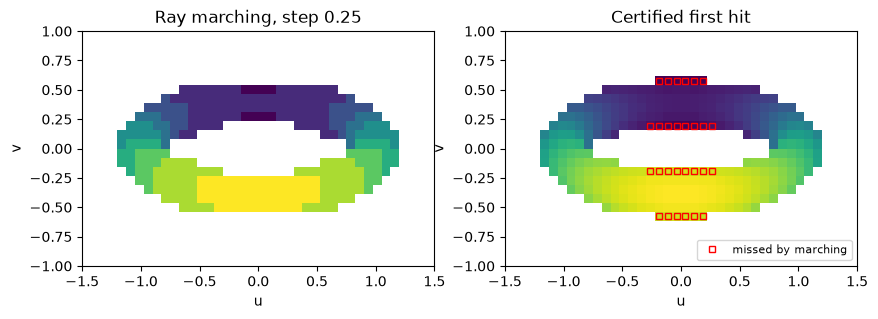

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
extent = [-1.5, 1.5, -1, 1]
axes[0].imshow(marched_depth, origin="lower", extent=extent, cmap="viridis_r")
axes[0].set_title("Ray marching, step 0.25")
axes[1].imshow(certified_depth, origin="lower", extent=extent, cmap="viridis_r")
miss_rows, miss_cols = np.nonzero(missed)
axes[1].plot(-1.5 + 3 * (miss_cols + 0.5) / columns, -1 + 2 * (miss_rows + 0.5) / rows,
             "rs", markersize=4, fillstyle="none", label="missed by marching")
axes[1].set_title("Certified first hit")
axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.set(xlabel="u", ylabel="v")
plt.close(fig)
display(fig)

The missed pixels lie on the silhouette, where rays cross only a thin part of the tube. A smaller step reduces the holes but never proves their absence. The certified renderer either proves the first hit, proves a miss, or says "uncertain".

# Part B · Wilkinson's polynomial

$$W(x)=(x-1)(x-2)\cdots(x-20)=x^{20}-210x^{19}+\dots+20!$$

Its roots are obviously 1, …, 20. In 1959 Wilkinson found that computing them from the **expanded** coefficients is extremely ill-conditioned. We revisit this with certificates.

In [9]:
coefficients = [Fraction(1)]                 # index = power of x
for k in range(1, 21):                       # multiply by (x - k)
    shifted = [Fraction(0)] + coefficients
    coefficients = [a - k*b for a, b in zip(shifted, coefficients + [Fraction(0)])]

print("x^19 coefficient:", coefficients[19], "  constant term:", coefficients[0])
largest = max(abs(c) for c in coefficients)
print(f"largest coefficient: {float(largest):.3e} (binary64 integers are exact only below 2^53 = {2.0**53:.3e})")

x^19 coefficient: -210   constant term: 2432902008176640000
largest coefficient: 1.380e+19 (binary64 integers are exact only below 2^53 = 9.007e+15)


## What a floating-point solver reports

NumPy's `roots` computes eigenvalues of a companion matrix in binary64.

In [10]:
float_roots = np.sort(np.roots([float(c) for c in reversed(coefficients)]).real)
errors = np.abs(float_roots - np.arange(1, 21))
print("worst error:", f"{errors.max():.3e}", "near x =", int(np.argmax(errors)) + 1)

worst error: 8.524e-02 near x = 14


The worst root is wrong by about 0.07. Is that because **the coefficients** were rounded when stored as binary64 (the problem changed), or because **the algorithm** loses accuracy (the solution of the stored problem is computed badly)? Certification can tell these apart: we certify the roots of the *stored* polynomial exactly.

## A certificate that works with huge coefficients

Interval Horner evaluation of W on an interval overestimates enormously: coefficients of size 10¹⁹ cancel to values of size 10¹². We use two tools that match Lectures 07 and 09.

**Taylor form.** Rewrite the polynomial around the midpoint m of X: W(m + h) = Σ cₖ hᵏ, with the cₖ computed exactly. For |h| ≤ ρ,

$$W(X)\subseteq\Big[c_0-\sum_{k\ge1}|c_k|\rho^k,\;c_0+\sum_{k\ge1}|c_k|\rho^k\Big].$$

This is the polynomial version of the mean-value form: the large terms enter only through the exact point value c₀.

**Sign-change certificate.** If W has opposite signs at the endpoints of X (exact rational evaluation) and the Taylor form shows W′(X) excludes 0, then W has **exactly one** root in X.

We plug this decision into `isolate_roots` through its `inspect` hook. Bisection points stay simple rationals, so the exact arithmetic stays cheap.

In [11]:
def shift(coeffs, m):
    """Coefficients of p(m + h) in powers of h, by repeated synthetic division."""
    c = list(coeffs)
    for i in range(len(c) - 1):
        for j in range(len(c) - 2, i - 1, -1):
            c[j] = c[j] + m * c[j + 1]
    return c

def taylor_form(coeffs, X):
    c = shift(coeffs, X.midpoint())
    rho = X.width() / 2
    spread = sum(abs(c[k]) * rho**k for k in range(1, len(c)))
    return Interval(c[0] - spread, c[0] + spread)

def value_at(coeffs, x):
    total = Fraction(0)
    for c in reversed(coeffs):
        total = total * x + c
    return total

def sign_change_inspector(coeffs):
    slope_coeffs = [k * c for k, c in enumerate(coeffs)][1:]
    def inspect(evaluate, derivative, X):
        image = taylor_form(coeffs, X)
        if not image.contains(0):
            return RootDecision(X, image, "excluded_range")
        slopes = taylor_form(slope_coeffs, X)
        opposite = value_at(coeffs, X.lo) * value_at(coeffs, X.hi) < 0
        if opposite and not slopes.contains(0):
            return RootDecision(X, image, "certified", slopes, retained=X)
        return RootDecision(X, image, "split", slopes)
    return inspect

def all_real_roots(coeffs, domain):
    return isolate_roots(None, None, domain, tolerance=Fraction(1, 10**12),
                         max_steps=5000, inspect=sign_change_inspector(coeffs))

The domain [1/3, 68/3] is chosen so that no bisection point is an integer (all points have a factor 3 in the denominator). Otherwise an exact root at a bisection point would give a zero endpoint value, which this simple certificate does not handle.

In [12]:
DOMAIN = Interval(Fraction(1, 3), Fraction(68, 3))
exact = all_real_roots(coefficients, DOMAIN)
print("exact W:", exact.status, "-", len(exact.certified), "certified roots,", len(exact.decisions), "decisions")

exact W: complete - 20 certified roots, 141 decisions


**Refining.** A certified interval has a sign change, so plain bisection with exact signs shrinks it as far as we like while keeping the root inside.

In [13]:
def refine(coeffs, X, width=Fraction(1, 10**15)):
    lo, hi = X.lo, X.hi
    lo_sign = value_at(coeffs, lo) > 0
    while hi - lo > width:
        mid = (lo + hi) / 2
        if (value_at(coeffs, mid) > 0) == lo_sign:
            lo = mid
        else:
            hi = mid
    return Interval(lo, hi)

stored = [Fraction(float(c)) for c in coefficients]     # what binary64 actually stores
print("coefficients changed by storing in binary64:", sum(a != b for a, b in zip(coefficients, stored)))
stored_search = all_real_roots(stored, DOMAIN)
print("stored W:", stored_search.status, "-", len(stored_search.certified), "certified real roots")
distance = max(max(abs(refine(stored, d.retained).lo - k), abs(refine(stored, d.retained).hi - k))
               for k, d in zip(range(1, 21), stored_search.certified))
print(f"every root of the stored polynomial is within {float(distance):.1e} of an integer")
print(f"NumPy's worst error is {errors.max() / float(distance):.0f} times larger")

coefficients changed by storing in binary64: 5


stored W: complete - 20 certified real roots
every root of the stored polynomial is within 6.2e-04 of an integer
NumPy's worst error is 138 times larger


**Conclusion for the floating-point solver.** The stored polynomial still has 20 real roots. Storing the coefficients in binary64 moved them by less than 10⁻³, which already shows the ill-conditioning: relative coefficient changes of 10⁻¹⁶ moved the roots by 10⁻⁴. NumPy's error is still about a hundred times larger, so most of it is **algorithmic**: the binary64 eigenvalue computation perturbs the problem more than storing the coefficients did. Exact certification separated the two error sources, which is the conditioning-versus-stability distinction from Lecture 03.

## Wilkinson's perturbation

Wilkinson changed the x¹⁹ coefficient from −210 to −210 − 2⁻²³. What happens to the real roots?

In [14]:
perturbed = list(coefficients)
perturbed[19] = perturbed[19] - Fraction(1, 2**23)
perturbed_search = all_real_roots(perturbed, DOMAIN)
print("perturbed W:", perturbed_search.status, "-", len(perturbed_search.certified), "certified real roots")
for d in perturbed_search.certified:
    root = refine(perturbed, d.retained, Fraction(1, 10**8))
    print(f"   {float(root.lo):.7f}")

perturbed W: complete - 10 certified real roots
   1.0000000
   2.0000000
   3.0000000
   4.0000000
   4.9999999
   6.0000069
   6.9996972
   8.0072676
   8.9172502
   20.8469081


Status `complete` means every part of [1/3, 68/3] was either excluded or certified. So the perturbed polynomial has **exactly ten** real roots in this interval. The other ten have left the real axis as complex pairs. A relative coefficient change of about 6·10⁻¹⁰ moved roots by more than 1: the roots are hopelessly ill-conditioned, whatever algorithm we use.

The claim is limited to [1/3, 68/3]. A statement about all real numbers would need a separate bound on where roots can be (Exercise 4).

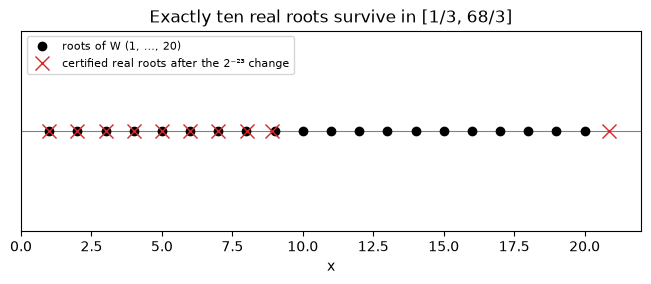

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.6))
xs = np.linspace(0.5, 21.5, 4000)
ax.axhline(0, color="gray", linewidth=0.8)
ax.plot(np.arange(1, 21), np.zeros(20), "o", color="black", label="roots of W (1, …, 20)")
perturbed_roots = [float(refine(perturbed, d.retained, Fraction(1, 10**6)).lo) for d in perturbed_search.certified]
ax.plot(perturbed_roots, np.zeros(len(perturbed_roots)), "x", color="tab:red", markersize=10,
        label="certified real roots after the 2⁻²³ change")
ax.set(yticks=[], xlabel="x", xlim=(0, 22), title="Exactly ten real roots survive in [1/3, 68/3]")
ax.legend(loc="upper left", fontsize=8)
plt.close(fig)
display(fig)

## Exercises

1. **Step size.** Rerun Part A with marching steps 0.1 and 0.05. Count missed pixels. Can any finite step guarantee no holes for every ray? Explain using a grazing ray.
2. **Shading with guarantees.** For hits, the certified enclosure gives a depth interval. Find the pixel with the widest depth enclosure and explain why it is wide.
3. **A smaller perturbation.** Repeat the perturbation experiment with 2⁻³⁰ and 2⁻⁴⁰. How many real roots survive? Plot the count against the exponent.
4. **All real roots.** Cauchy's bound says every root satisfies |x| ≤ 1 + max |aₖ/a₂₀|. Use it to choose a domain that makes the "exactly ten real roots" statement global. What does this do to the running time, and why?